## Cell 0: setup 

In [2]:
# 10_protocol_ladder - Cell 0: setup (read-only access to the frozen strict-protocol results)
from pathlib import Path
import sys, yaml, json, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, confusion_matrix

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from circmtl.graph import GraphData
with open(PROJECT_ROOT / "configs" / "paths.yaml", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)
D = PROJECT_ROOT / cfg["outputs"]["processed_dir"] / "dataset_v1"
OLD = D / "train_results"                         # frozen strict-protocol results: READ ONLY
OUT = D / "train_results_ladder"; OUT.mkdir(exist_ok=True)
assert OLD.exists() and OLD != OUT
LAD = yaml.safe_load(open(PROJECT_ROOT / "configs" / "protocol_ladder.yaml", encoding="utf-8"))   # fails if the yaml is missing or invalid
gd = GraphData(D, D / "graph")
print("ladder yaml loaded; runs:", list(LAD["runs"]), "| metrics:", LAD["metrics"])
print("frozen results:", len(list(OLD.glob("pred_*.csv"))), "prediction files")

ladder yaml loaded; runs: ['S0', 'B', 'A', 'C', 'X'] | metrics: ['AUROC', 'AUPR', 'accuracy', 'precision', 'recall', 'specificity', 'F1', 'MCC', 'confusion matrix', 'ROC curve']
frozen results: 165 prediction files


## Cell 1:  metric report

S0 predictions: 257584 rows | ['M1', 'M2', 'M3'] | seeds [np.int64(0), np.int64(1), np.int64(2)]
[S0] disease task | degree_matched negatives | threshold = 0.0 (model logit) | mean over seeds (range)
                              AUROC                 AUPR             Accuracy            Precision               Recall          Specificity                   F1                  MCC
M1              0.521 (0.515-0.525)  0.514 (0.508-0.521)  0.514 (0.509-0.521)  0.522 (0.513-0.531)  0.340 (0.324-0.357)  0.689 (0.679-0.701)  0.411 (0.399-0.427)  0.030 (0.019-0.045)
M2              0.520 (0.500-0.535)  0.511 (0.495-0.520)  0.514 (0.504-0.519)  0.520 (0.506-0.528)  0.352 (0.334-0.371)  0.676 (0.666-0.686)  0.420 (0.402-0.435)  0.029 (0.008-0.039)
M3              0.530 (0.516-0.543)  0.523 (0.515-0.530)  0.520 (0.508-0.532)  0.528 (0.510-0.544)  0.382 (0.343-0.404)  0.658 (0.612-0.695)  0.442 (0.417-0.460)  0.042 (0.016-0.067)
disease_degree  0.510 (0.508-0.513)  0.512 (0.511-0.513)            

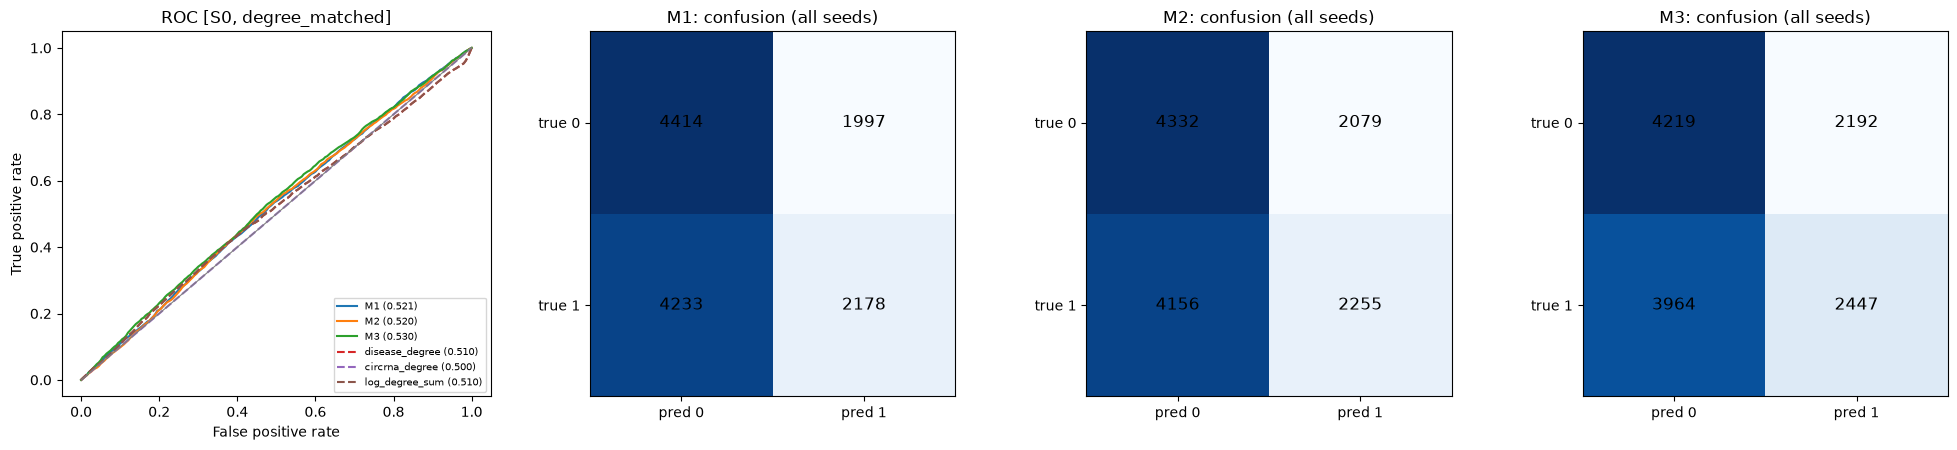

[S0] disease task | random negatives | threshold = 0.0 (model logit) | mean over seeds (range)
                              AUROC                 AUPR             Accuracy            Precision               Recall          Specificity                   F1                     MCC
M1              0.513 (0.500-0.524)  0.487 (0.474-0.497)  0.480 (0.476-0.483)  0.473 (0.469-0.475)  0.340 (0.324-0.357)  0.621 (0.595-0.642)  0.395 (0.385-0.405)  -0.041 (-0.049--0.036)
M2              0.502 (0.480-0.518)  0.476 (0.458-0.490)  0.474 (0.456-0.489)  0.465 (0.442-0.485)  0.352 (0.334-0.371)  0.595 (0.578-0.606)  0.400 (0.380-0.421)  -0.055 (-0.091--0.023)
M3              0.551 (0.542-0.557)  0.511 (0.507-0.520)  0.508 (0.499-0.517)  0.511 (0.498-0.522)  0.382 (0.343-0.404)  0.635 (0.615-0.654)  0.437 (0.407-0.452)    0.017 (-0.003-0.035)
disease_degree  0.820 (0.816-0.822)  0.823 (0.814-0.832)                  n/a                  n/a                  n/a                  n/a                  n/a

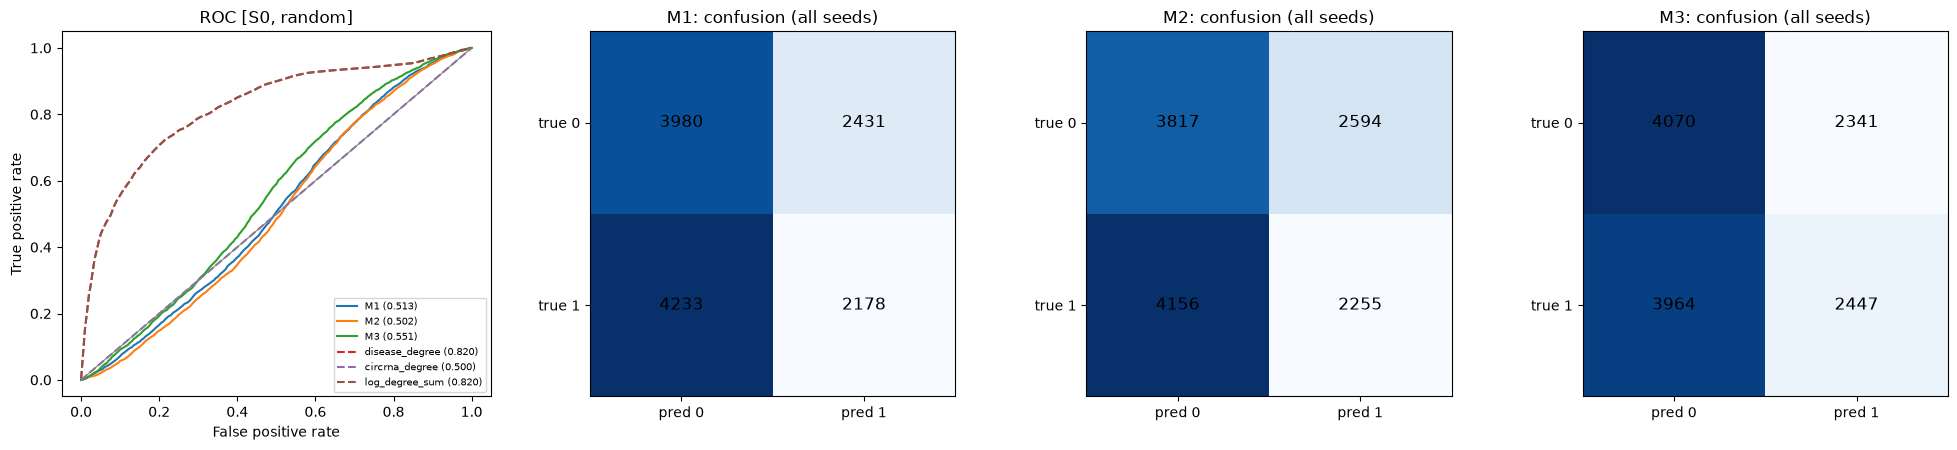

In [8]:
# 10_protocol_ladder - Cell 1: metric report (reusable for every run) and the S0 reference row
def mcc_from(tp, tn, fp, fn):
    den = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return float((tp * tn - fp * fn) / den) if den > 0 else 0.0

def baseline_scores(d, kind):
    """popularity baselines from the fold's TRAINING pairs only; d has columns seed, fold, c, t and a RangeIndex"""
    out = np.zeros(len(d))
    for (s, k), ix in d.groupby(["seed", "fold"]).indices.items():
        tr = gd.load_fold(s, k)["disease_train"]
        dd = np.bincount(tr[:, 1], minlength=gd.N["disease"]); cd = np.bincount(tr[:, 0], minlength=gd.N["circRNA"])
        c, t = d["c"].to_numpy()[ix], d["t"].to_numpy()[ix]
        out[ix] = {"disease_degree": dd[t], "circrna_degree": cd[c], "log_degree_sum": np.log1p(dd[t]) + np.log1p(cd[c])}[kind]
    return out

def report(P, models, tag, scheme="degree_matched", task="disease", threshold=0.0,
           baselines=("disease_degree", "circrna_degree", "log_degree_sum")):
    d = P[(P["task"] == task) & (P["scheme"] == scheme) & P["model"].isin(models)].reset_index(drop=True)
    assert set(models) <= set(d["model"]), f"missing predictions for {set(models) - set(d['model'])}"
    base = d[d["model"] == models[0]][["seed", "fold", "c", "t", "y"]].reset_index(drop=True)
    keep = ["model", "seed", "fold", "c", "t", "y", "score", "score_rank"] + (["threshold"] if "threshold" in d else [])
    parts = [d[keep]]
    for b in baselines:
        x = base.copy(); x["score"] = baseline_scores(x, b); x["model"] = b
        x["score_rank"] = x.groupby(["seed", "fold"])["score"].rank(pct=True)
        parts.append(x)
    A = pd.concat(parts, ignore_index=True)
    rows = []
    for (m, s), g in A.groupby(["model", "seed"], sort=False):
        r = {"model": m, "seed": s, "AUROC": roc_auc_score(g["y"], g["score_rank"]), "AUPR": average_precision_score(g["y"], g["score_rank"])}
        if m in models:                                              # threshold metrics only for the models
            thr = g["threshold"].to_numpy() if "threshold" in g else threshold      # per-fold validation-chosen threshold if present
            yhat = (g["score"].to_numpy() > thr).astype(int)
            tn, fp, fn, tp = confusion_matrix(g["y"], yhat, labels=[0, 1]).ravel()
            r.update(TP=tp, FP=fp, TN=tn, FN=fn, Accuracy=(tp + tn) / len(g),
                     Precision=tp / (tp + fp) if tp + fp else np.nan, Recall=tp / (tp + fn) if tp + fn else np.nan,
                     Specificity=tn / (tn + fp) if tn + fp else np.nan, F1=2 * tp / (2 * tp + fp + fn) if tp else 0.0,
                     MCC=mcc_from(tp, tn, fp, fn))
        rows.append(r)
    per_seed = pd.DataFrame(rows)
    cols = [c for c in ["AUROC", "AUPR", "Accuracy", "Precision", "Recall", "Specificity", "F1", "MCC"] if c in per_seed]
    order = list(models) + list(baselines)
    tab = {}
    for c in cols:
        agg = per_seed.groupby("model")[c].agg(["mean", "min", "max"])
        tab[c] = [f"{agg.loc[m, 'mean']:.3f} ({agg.loc[m, 'min']:.3f}-{agg.loc[m, 'max']:.3f})" if m in agg.index and pd.notna(agg.loc[m, 'mean']) else "n/a" for m in order]
    table = pd.DataFrame(tab, index=order)
    thr_label = "chosen on validation, per fold" if "threshold" in d else f"{threshold} (model logit)"
    print(f"[{tag}] disease task | {scheme} negatives | threshold = {thr_label} | mean over seeds (range)")
    print(table.to_string())
    prev = A[A["model"] == models[0]]["y"].mean()
    print(f"all-positive reference: accuracy {prev:.3f} | precision {prev:.3f} | recall 1.000 | F1 {2 * prev / (1 + prev):.3f} | MCC 0.000")
    table.to_csv(OUT / f"report_{tag}_{scheme}.csv")
    per_seed.to_csv(OUT / f"report_{tag}_{scheme}_per_seed.csv", index=False)

    grid = np.linspace(0, 1, 201)
    fig, axes = plt.subplots(1, 1 + len(models), figsize=(5 * (1 + len(models)), 4.6))
    for m, g_m in A.groupby("model", sort=False):
        tprs = [np.interp(grid, *roc_curve(g["y"], g["score_rank"])[:2]) for _, g in g_m.groupby("seed")]
        a = per_seed.loc[per_seed["model"] == m, "AUROC"].mean()
        axes[0].plot(grid, np.mean(tprs, 0), ls="--" if m in baselines else "-", label=f"{m} ({a:.3f})")
    axes[0].plot([0, 1], [0, 1], color="grey", lw=0.8)
    axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title=f"ROC [{tag}, {scheme}]"); axes[0].legend(fontsize=7, loc="lower right")
    for ax, m in zip(axes[1:], models):
        r = per_seed[per_seed["model"] == m][["TN", "FP", "FN", "TP"]].sum()
        cm = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]]); ax.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2): ax.text(j, i, f"{int(cm[i, j])}", ha="center", va="center", fontsize=12)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["pred 0", "pred 1"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["true 0", "true 1"])
        ax.set_title(f"{m}: confusion (all seeds)")
    plt.tight_layout(); plt.savefig(OUT / f"report_{tag}_{scheme}.png", dpi=200); plt.show()
    return table, per_seed

# S0 = the frozen strict-protocol predictions (read-only)
P_S0 = pd.concat([pd.read_csv(f) for m in ("M1", "M2", "M3") for f in sorted(OLD.glob(f"pred_{m}_seed*_fold*.csv"))], ignore_index=True)
print("S0 predictions:", len(P_S0), "rows |", sorted(P_S0["model"].unique()), "| seeds", sorted(P_S0["seed"].unique()))
S0_deg, _ = report(P_S0, ["M1", "M2", "M3"], tag="S0", scheme="degree_matched")
S0_rnd, _ = report(P_S0, ["M1", "M2", "M3"], tag="S0", scheme="random")

## Cell 2: what exactly are the frozen test negatives?

In [3]:
# 10_protocol_ladder - Cell 2: what exactly are the frozen test negatives? (read-only; decides what run B needs)
def neg_profile(fd, scheme):
    pos, neg = fd["disease_test"], fd[f"neg_test_{scheme}"]
    known = {tuple(p) for key in ("disease_train", "disease_val", "disease_test") for p in fd[key]}
    test_c, train_c = set(pos[:, 0]), set(fd["train"])
    dd = np.bincount(fd["disease_train"][:, 1], minlength=gd.N["disease"])
    same_len = len(pos) == len(neg)
    return {
        "neg_per_pos": len(neg) / len(pos),
        "neg_circ_in_test_circ": np.mean([c in test_c for c in neg[:, 0]]),
        "neg_circ_in_train_circ": np.mean([c in train_c for c in neg[:, 0]]),
        "per_circ_counts_match": float(same_len and np.array_equal(np.bincount(neg[:, 0], minlength=gd.N["circRNA"]),
                                                                    np.bincount(pos[:, 0], minlength=gd.N["circRNA"]))),
        "neg_is_known_positive": np.mean([tuple(p) in known for p in neg]),
        "mean_train_deg_pos_disease": dd[pos[:, 1]].mean(),
        "mean_train_deg_neg_disease": dd[neg[:, 1]].mean(),
        "neg_duplicate_pairs": 1 - len({tuple(p) for p in neg}) / len(neg),
    }

rows = []
for scheme in ("degree_matched", "random"):
    for s in range(3):
        for k in range(5):
            rows.append({"scheme": scheme, **neg_profile(gd.load_fold(s, k), scheme)})
prof = pd.DataFrame(rows).groupby("scheme").mean().T
print("mean over the 15 frozen folds:\n", prof.round(3).to_string())
prof.to_csv(OUT / "frozen_test_negative_profile.csv")

mean over the 15 frozen folds:
 scheme                      degree_matched  random
neg_per_pos                          1.000   1.000
neg_circ_in_test_circ                1.000   1.000
neg_circ_in_train_circ               0.000   0.000
per_circ_counts_match                1.000   1.000
neg_is_known_positive                0.000   0.000
mean_train_deg_pos_disease          31.651  31.651
mean_train_deg_neg_disease          30.011   6.318
neg_duplicate_pairs                  0.000   0.000


## Cell 3: frozen uniform-pair negatives for all 15 folds + leak assertions

In [4]:
# 10_protocol_ladder - Cell 3: run B, step 2a - frozen uniform-pair negatives for all 15 folds + leak assertions (no training)
from circmtl import ladder as L
FZ = OUT / "frozen_B"; FZ.mkdir(exist_ok=True)
rows = []
for s in range(3):
    for k in range(5):
        fd = gd.load_fold(s, k)
        neg_val, neg_test = L.frozen_uniform_negatives(gd, fd, s, k)
        L.check_fold_B(gd, fd, neg_val, neg_test)                      # raises AssertionError if any leak assertion fails
        np.savez(FZ / f"negB_seed{s}_fold{k}.npz", neg_val=neg_val, neg_test=neg_test)
        dd = np.bincount(fd["disease_train"][:, 1], minlength=gd.N["disease"])
        pos, neg = fd["disease_test"], neg_test
        y = np.r_[np.ones(len(pos)), np.zeros(len(neg))]
        rows.append({"seed": s, "fold": k, "n_pos": len(pos), "n_neg": len(neg),
                     "neg_circ_in_test": np.mean(np.isin(neg[:, 0], fd["test"])),
                     "per_circ_counts_match": float(np.array_equal(np.bincount(neg[:, 0], minlength=gd.N["circRNA"]),
                                                                    np.bincount(pos[:, 0], minlength=gd.N["circRNA"]))),
                     "mean_deg_pos_disease": dd[pos[:, 1]].mean(), "mean_deg_neg_disease": dd[neg[:, 1]].mean(),
                     "AUROC_disease_degree": roc_auc_score(y, np.r_[dd[pos[:, 1]], dd[neg[:, 1]]])})
sumB = pd.DataFrame(rows)
print("all 15 folds passed the leak assertions\n")
print(sumB.drop(columns=["seed", "fold"]).mean().round(3).to_string())
sumB.to_csv(FZ / "frozen_B_profile.csv", index=False)

all 15 folds passed the leak assertions

n_pos                    427.400
n_neg                    427.400
neg_circ_in_test           1.000
per_circ_counts_match      0.000
mean_deg_pos_disease      31.651
mean_deg_neg_disease       6.492
AUROC_disease_degree       0.818


## Cell 4: model 

In [5]:
# 10_protocol_ladder - Cell 4: model and training (verbatim copy of 08_train Cells 1-2 and the _frame helper; train_one gets three hooks; defaults reproduce 08_train)
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import RGCNConv
from circmtl.graph import RELS, AUX
device = "cuda" if torch.cuda.is_available() else "cpu"

class CircMTL(nn.Module):
    """Input projections -> 2-layer RGCN (6 relations: 3 forward + 3 reverse) -> DistMult per forward relation."""
    def __init__(self, N, in_dim, hidden=128, layers=2, num_bases=3, dropout=0.2):
        super().__init__()
        self.proj = nn.Linear(in_dim, hidden)                                    # circRNA features
        self.emb = nn.ModuleDict({t: nn.Embedding(N[t], hidden) for t in ("disease", "mirna", "rbp")})
        for e in self.emb.values():
            nn.init.normal_(e.weight, std=0.1)
        self.convs = nn.ModuleList([RGCNConv(hidden, hidden, num_relations=2 * len(RELS), num_bases=num_bases)
                                    for _ in range(layers)])
        self.rel = nn.ParameterDict({r: nn.Parameter(torch.full((hidden,), 0.1)) for r in RELS})   # small start: loss begins near ln 2   # DistMult diagonals
        self.dropout = dropout

    def encode(self, x, edge_index, edge_type):
        # node order must match GraphData.offset: circRNA, disease, mirna, rbp
        h = torch.cat([self.proj(x), self.emb["disease"].weight, self.emb["mirna"].weight, self.emb["rbp"].weight], 0)
        h = F.dropout(h, self.dropout, self.training)
        for i, conv in enumerate(self.convs):
            h = conv(h, edge_index, edge_type)
            if i < len(self.convs) - 1:
                h = F.dropout(F.relu(h), self.dropout, self.training)
        return h

    def score(self, h, r, gpairs):
        return (h[gpairs[:, 0]] * self.rel[r] * h[gpairs[:, 1]]).sum(-1)

TRAIN = dict(hidden=128, num_bases=3, dropout=0.2, lr=1e-3, weight_decay=1e-4,
             max_epochs=300, warmup=20, min_epochs=60, patience=40, neg_k=5)
HEADS = {"M1": ["disease"], "M2": ["disease"], "M3": ["disease", "mirna", "rbp"],
         "M3-RBP": ["disease", "rbp"], "M3-miRNA": ["disease", "mirna"]}
graph_of = lambda m: "M1" if m == "M1" else "M3"          # M1: disease-only graph; all others: full graph

def T(a):
    return torch.from_numpy(a).to(device)

def bce_balanced(s_pos, s_neg):
    return 0.5 * (F.binary_cross_entropy_with_logits(s_pos, torch.ones_like(s_pos)) +
                  F.binary_cross_entropy_with_logits(s_neg, torch.zeros_like(s_neg)))

def score_pairs(model, h, r, pos, neg):
    with torch.no_grad():
        sp = model.score(h, r, T(gd.global_pairs(r, pos))).cpu().numpy()
        sn = model.score(h, r, T(gd.global_pairs(r, neg))).cpu().numpy()
    y, s = np.r_[np.ones(len(sp)), np.zeros(len(sn))], np.r_[sp, sn]
    return roc_auc_score(y, s), average_precision_score(y, s), sp, sn

def train_one_l(fd, model_name, aux_w=0.5, seed=0, cfg=TRAIN, disease_neg_fn=None, val_neg=None):
    """Same as 08_train.train_one, plus: disease_neg_fn(sup, rng) -> disease training negatives; val_neg -> validation negatives.
    Defaults reproduce 08_train. Returns an extra element: validation scores (pos, neg) of the selected state."""
    torch.manual_seed(seed)
    rng_split = np.random.default_rng(seed)                                       # same graphs for M2 and M3
    rng_neg = {r: np.random.default_rng(seed + 1 + i) for i, r in enumerate(RELS)} # same disease negatives too
    gm = graph_of(model_name)
    val_neg = fd["neg_val"] if val_neg is None else val_neg
    w = {r: (1.0 if r == "disease" else aux_w) for r in HEADS[model_name]}
    x = T(gd.features(fd))
    model = CircMTL(gd.N, x.shape[1], cfg["hidden"], num_bases=cfg["num_bases"], dropout=cfg["dropout"]).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    val_ei, val_et = gd.to_edge_tensors(gd.inference_graph(fd, "val", gm), device)
    best, hist = {"auc": -1.0, "epoch": 0, "state": None}, []
    for epoch in range(1, cfg["max_epochs"] + 1):
        model.train()
        mp, sup = gd.epoch_graph(fd, rng_split, gm)
        ei, et = gd.to_edge_tensors(mp, device)
        h = model.encode(x, ei, et)
        loss, parts = 0.0, {}
        for r, wr in w.items():
            neg = (disease_neg_fn(sup[r], rng_neg[r]) if (r == "disease" and disease_neg_fn is not None)
                   else gd.train_negatives(r, sup[r], fd[f"{r}_train"], rng_neg[r], k=cfg["neg_k"]))
            l = bce_balanced(model.score(h, r, T(gd.global_pairs(r, sup[r]))), model.score(h, r, T(gd.global_pairs(r, neg))))
            loss, parts[r] = loss + wr * l, l.item()
        opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            va = score_pairs(model, model.encode(x, val_ei, val_et), "disease", fd["disease_val"], val_neg)[0]
        hist.append({"epoch": epoch, "loss": float(loss), **{f"loss_{r}": v for r, v in parts.items()}, "val_auc": va})
        sm = float(np.mean([h_["val_auc"] for h_ in hist[-5:]]))           # 5-epoch moving average
        if epoch >= cfg["warmup"] and sm > best["auc"]:                    # ignore noise peaks before warm-up
            best = {"auc": sm, "epoch": epoch, "state": {k: v.detach().clone() for k, v in model.state_dict().items()}}
        elif epoch >= cfg["min_epochs"] and epoch - best["epoch"] >= cfg["patience"]:
            break
        elif epoch - best["epoch"] >= cfg["patience"]:
            break
    model.load_state_dict(best["state"]); model.eval()
    with torch.no_grad():                                                       # validation scores of the selected state (for the F1 threshold)
        _, _, vsp, vsn = score_pairs(model, model.encode(x, val_ei, val_et), "disease", fd["disease_val"], val_neg)
    return model, x, pd.DataFrame(hist), best, (vsp, vsn)

def _frame(task, scheme, pos, neg, sp, sn):
    return pd.DataFrame({"task": task, "scheme": scheme, "c": np.r_[pos[:, 0], neg[:, 0]], "t": np.r_[pos[:, 1], neg[:, 1]],
                         "y": np.r_[np.ones(len(pos), int), np.zeros(len(neg), int)], "score": np.r_[sp, sn]})

def predict_l(model, x, fd, model_name, test_neg, scheme="uniform_pair"):
    """Disease test scores WITH the test circRNAs' auxiliary edges (as in 08_train.predict), for one set of test negatives."""
    gm = graph_of(model_name)
    with torch.no_grad():
        hA = model.encode(x, *gd.to_edge_tensors(gd.inference_graph(fd, "test", gm, with_test_aux=True), device))
        _, _, sp, sn = score_pairs(model, hA, "disease", fd["disease_test"], test_neg)
    df = _frame("disease", scheme, fd["disease_test"], test_neg, sp, sn)
    df["score_rank"] = df.groupby(["task", "scheme"])["score"].rank(pct=True)
    return df

c:\Users\aeasa\anaconda3\envs\circmtl\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\aeasa\anaconda3\envs\circmtl\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Cell 5: regression check

In [6]:
# 10_protocol_ladder - Cell 5: regression check - the copy must reproduce the frozen run (seed 0, fold 0, M1) before any run-B training
fd = gd.load_fold(0, 0)
t0 = time.time()
model, x, hist, best, _ = train_one_l(fd, "M1", seed=0)                  # default arguments = the frozen setting
old = pd.read_csv(OLD / "pred_M1_seed0_fold0.csv")
o = old[(old["task"] == "disease") & (old["scheme"] == "degree_matched")]
with torch.no_grad():
    hA = model.encode(x, *gd.to_edge_tensors(gd.inference_graph(fd, "test", "M1", with_test_aux=True), device))
    auc_new = score_pairs(model, hA, "disease", fd["disease_test"], fd["neg_test_degree_matched"])[0]
res = pd.DataFrame({"copy": [best["epoch"], best["auc"], auc_new],
                    "frozen": [old["best_epoch"].iloc[0], old["val_auc"].iloc[0], roc_auc_score(o["y"], o["score"])]},
                   index=["best epoch", "validation AUROC (5-epoch avg)", "test AUROC (degree-matched)"])
res["difference"] = res["copy"] - res["frozen"]
print(res.round(4).to_string(), f"\n({time.time() - t0:.0f}s on {device})")
ok = abs(res.loc["validation AUROC (5-epoch avg)", "difference"]) < 0.005 and abs(res.loc["test AUROC (degree-matched)", "difference"]) < 0.005
print("REGRESSION CHECK:", "PASSED" if ok else "FAILED - do not run B; paste this table")

C:\Users\aeasa\AppData\Local\Temp\ipykernel_13160\1221900115.py:82: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  hist.append({"epoch": epoch, "loss": float(loss), **{f"loss_{r}": v for r, v in parts.items()}, "val_auc": va})


                                    copy    frozen  difference
best epoch                      205.0000  125.0000     80.0000
validation AUROC (5-epoch avg)    0.5559    0.5525      0.0034
test AUROC (degree-matched)       0.4978    0.5094     -0.0115 
(7s on cuda)
REGRESSION CHECK: FAILED - do not run B; paste this table


In [21]:
# 10_protocol_ladder - Cell 5b: decisive regression test - is train_one_l the same function as 08_train's train_one? (CPU runs are deterministic, GPU runs are not)
import json, re, warnings
warnings.filterwarnings("ignore", message="Converting a tensor with requires_grad")

# the ORIGINAL function, read from the frozen 08_train notebook itself (no retyping)
nb08 = json.load(open(PROJECT_ROOT / "notebooks" / "Final_notebook" / "08_train.ipynb", encoding="utf-8"))
src08 = next("".join(c["source"]) for c in nb08["cells"] if c["cell_type"] == "code" and "def train_one(" in "".join(c["source"]))
body = re.search(r"^def train_one\(.*?(?=^def |\Z)", src08, re.S | re.M).group(0)
exec(body.replace("def train_one(", "def train_one_orig(", 1))

def test_auc(model, x, fd):
    with torch.no_grad():
        hA = model.encode(x, *gd.to_edge_tensors(gd.inference_graph(fd, "test", "M1", with_test_aux=True), device))
        return score_pairs(model, hA, "disease", fd["disease_test"], fd["neg_test_degree_matched"])[0]

def summarize(name, out, fd):
    model, x, hist, best = out[:4]
    return {"run": name, "best epoch": best["epoch"], "val AUROC (avg)": best["auc"], "test AUROC": test_auc(model, x, fd)}

fd = gd.load_fold(0, 0)
old = pd.read_csv(OLD / "pred_M1_seed0_fold0.csv"); o = old[(old["task"] == "disease") & (old["scheme"] == "degree_matched")]
rows = [{"run": "frozen (saved file)", "best epoch": old["best_epoch"].iloc[0], "val AUROC (avg)": old["val_auc"].iloc[0], "test AUROC": roc_auc_score(o["y"], o["score"])}]
dev0, nthr0 = device, torch.get_num_threads()
try:
    for name, fn in (("GPU original #1", train_one_orig), ("GPU original #2", train_one_orig), ("GPU copy", train_one_l)):
        rows.append(summarize(name, fn(fd, "M1", seed=0), fd))
    device = "cpu"; torch.set_num_threads(1)                                    # CPU, one thread: deterministic
    for name, fn in (("CPU original #1", train_one_orig), ("CPU original #2", train_one_orig), ("CPU copy", train_one_l)):
        t0 = time.time(); rows.append(summarize(name, fn(fd, "M1", seed=0), fd)); print(f"  {name}: {time.time() - t0:.0f}s")
finally:
    device = dev0; torch.set_num_threads(nthr0)                                 # always restore the GPU setting
res = pd.DataFrame(rows); print(res.round(6).to_string(index=False))
c = res.set_index("run")
same = lambda a, b: bool(c.loc[a, "best epoch"] == c.loc[b, "best epoch"] and abs(c.loc[a, "val AUROC (avg)"] - c.loc[b, "val AUROC (avg)"]) < 1e-9 and abs(c.loc[a, "test AUROC"] - c.loc[b, "test AUROC"]) < 1e-9)
print("\nCPU is deterministic (original #1 == original #2):", same("CPU original #1", "CPU original #2"))
print("copy == original on CPU:                          ", same("CPU copy", "CPU original #1"))
print("GPU original #1 == original #2 (GPU noise):        ", same("GPU original #1", "GPU original #2"))

  CPU original #1: 9s
  CPU original #2: 9s
  CPU copy: 9s
                run  best epoch  val AUROC (avg)  test AUROC
frozen (saved file)         125         0.552546    0.509370
    GPU original #1          51         0.541321    0.510029
    GPU original #2          51         0.540425    0.510829
           GPU copy         125         0.553731    0.509952
    CPU original #1          55         0.556030    0.493701
    CPU original #2          55         0.556030    0.493701
           CPU copy          55         0.556030    0.493701

CPU is deterministic (original #1 == original #2): True
copy == original on CPU:                           True
GPU original #1 == original #2 (GPU noise):         False


## Cell 6:host-gene folds; uniform-pair negatives for training, validation and test (resumable)

In [15]:
# 10_protocol_ladder - Cell 6: run B - host-gene folds; uniform-pair negatives for training, validation and test (resumable)
from circmtl import ladder as L
OUTB = OUT / "pred_B"; OUTB.mkdir(exist_ok=True)
MODELS_B, AUX_W = ["M1", "M2", "M3"], [0.1, 0.5, 1.0]
t0, log = time.time(), []
for m in MODELS_B:
    for s in range(3):
        for k in range(5):
            fn = OUTB / f"pred_{m}_seed{s}_fold{k}.csv"
            if fn.exists():
                continue                                                    # resume: finished runs are kept
            fd = gd.load_fold(s, k)
            z = np.load(OUT / "frozen_B" / f"negB_seed{s}_fold{k}.npz")
            neg_val, neg_test = z["neg_val"], z["neg_test"]
            L.check_fold_B(gd, fd, neg_val, neg_test)                       # leak assertions before every fit
            tcodes = L.codes(fd["disease_train"][:, 0], fd["disease_train"][:, 1], gd.N["disease"])

            def neg_fn(sup, rng, fd=fd, tcodes=tcodes):                     # uniform training negatives; training positives excluded only
                neg = L.uniform_train_negatives(gd.N["disease"], sup, fd["train"], tcodes, rng, k=TRAIN["neg_k"])
                L.check_train_negatives(gd.N["disease"], neg, fd)
                return neg

            weights = AUX_W if any(r in HEADS[m] for r in AUX) else [None]
            cands = []
            for w in weights:
                model, x, hist, best, vs = train_one_l(fd, m, aux_w=(w or 0.0), seed=s, disease_neg_fn=neg_fn, val_neg=neg_val)
                cands.append((best["auc"], w, model, x, best["epoch"], vs))
            val_auc, w, model, x, ep, (vsp, vsn) = max(cands, key=lambda c: c[0])        # chosen on VALIDATION only
            thr, vf1 = L.best_f1_threshold(np.r_[np.ones(len(vsp)), np.zeros(len(vsn))], np.r_[vsp, vsn])
            predict_l(model, x, fd, m, neg_test).assign(model=m, seed=s, fold=k, aux_w=w, best_epoch=ep,
                                                         val_auc=val_auc, threshold=thr, val_f1=vf1).to_csv(fn, index=False)
            log.append({"model": m, "seed": s, "fold": k, "aux_w": w, "best_epoch": ep, "val_auc": round(val_auc, 3), "thr": round(thr, 3), "val_f1": round(vf1, 3)})
            print(f"  {m:3s} seed {s} fold {k} | w {w} | best epoch {ep:3d} | val {val_auc:.3f} | thr {thr:+.2f} | {time.time() - t0:5.0f}s")
if log:
    pd.DataFrame(log).to_csv(OUTB / "run_log.csv", mode="a", index=False, header=not (OUTB / "run_log.csv").exists())
print(f"done in {time.time() - t0:.0f}s")

  M1  seed 0 fold 0 | w None | best epoch  84 | val 0.814 | thr -0.30 |     3s
  M1  seed 0 fold 1 | w None | best epoch  47 | val 0.791 | thr -0.08 |     5s
  M1  seed 0 fold 2 | w None | best epoch  84 | val 0.817 | thr +0.01 |     8s
  M1  seed 0 fold 3 | w None | best epoch  82 | val 0.818 | thr +0.31 |    12s
  M1  seed 0 fold 4 | w None | best epoch 135 | val 0.802 | thr -0.93 |    17s
  M1  seed 1 fold 0 | w None | best epoch 131 | val 0.789 | thr -0.51 |    22s
  M1  seed 1 fold 1 | w None | best epoch 125 | val 0.824 | thr -0.14 |    26s
  M1  seed 1 fold 2 | w None | best epoch  98 | val 0.789 | thr +0.39 |    30s
  M1  seed 1 fold 3 | w None | best epoch 117 | val 0.819 | thr +0.19 |    34s
  M1  seed 1 fold 4 | w None | best epoch 118 | val 0.806 | thr +0.17 |    38s
  M1  seed 2 fold 0 | w None | best epoch  73 | val 0.829 | thr +0.79 |    41s
  M1  seed 2 fold 1 | w None | best epoch 119 | val 0.805 | thr +0.50 |    45s
  M1  seed 2 fold 2 | w None | best epoch 140 | val 

## Cell 7: B report

B predictions: 38466 rows | validation-chosen thresholds: {'count': 45.0, 'mean': 0.04, 'std': 0.45, 'min': -1.48, '25%': -0.18, '50%': 0.11, '75%': 0.31, 'max': 0.92}
[B] disease task | uniform_pair negatives | threshold = chosen on validation, per fold | mean over seeds (range)
                              AUROC                 AUPR             Accuracy            Precision               Recall          Specificity                   F1                  MCC
M1              0.805 (0.799-0.809)  0.800 (0.796-0.807)  0.721 (0.700-0.735)  0.689 (0.655-0.719)  0.811 (0.772-0.847)  0.630 (0.554-0.699)  0.744 (0.739-0.749)  0.451 (0.419-0.472)
M2              0.802 (0.799-0.805)  0.797 (0.792-0.804)  0.714 (0.714-0.714)  0.679 (0.677-0.682)  0.813 (0.804-0.821)  0.615 (0.608-0.624)  0.740 (0.738-0.742)  0.437 (0.436-0.439)
M3              0.805 (0.802-0.810)  0.801 (0.796-0.805)  0.716 (0.710-0.724)  0.681 (0.670-0.695)  0.815 (0.796-0.829)  0.617 (0.591-0.651)  0.741 (0.741-0.742)  0.441 (

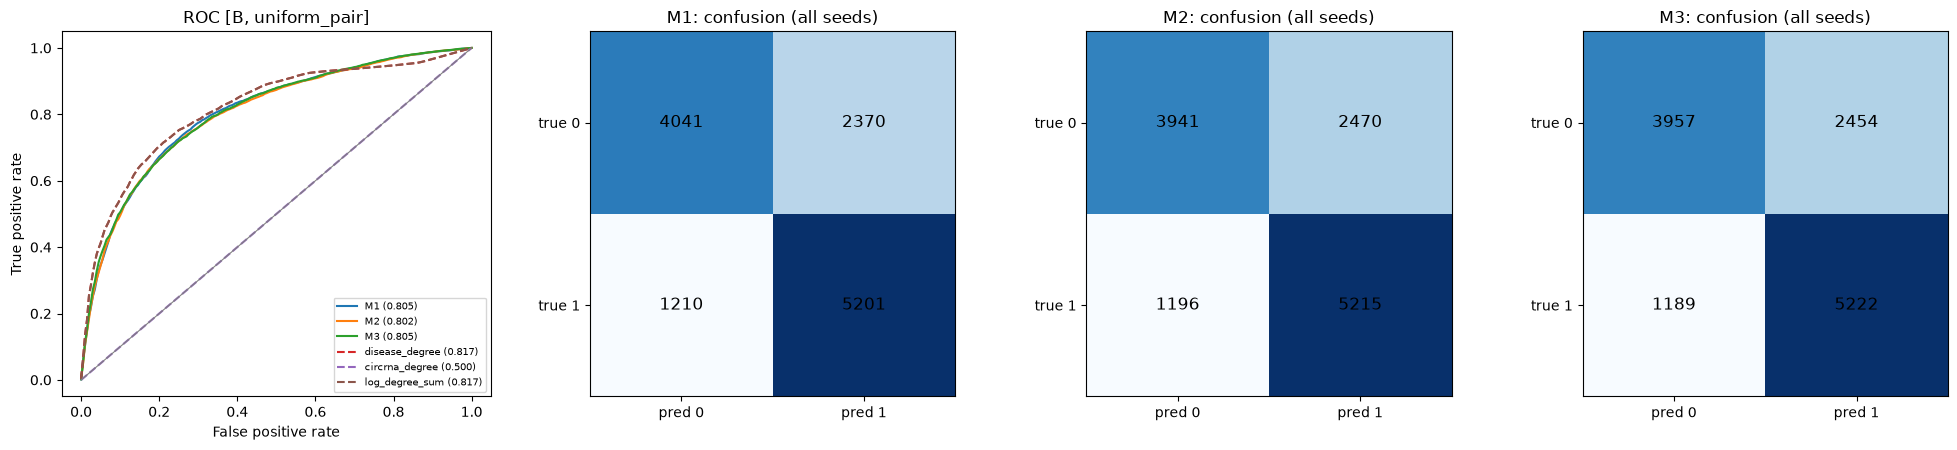

In [16]:
# 10_protocol_ladder - Cell 7: run B report
P_B = pd.concat([pd.read_csv(f) for m in ("M1", "M2", "M3") for f in sorted((OUT / "pred_B").glob(f"pred_{m}_seed*_fold*.csv"))], ignore_index=True)
print("B predictions:", len(P_B), "rows | validation-chosen thresholds:", P_B.groupby(["model", "seed", "fold"])["threshold"].first().describe().round(2).to_dict())
B_tab, B_seed = report(P_B, ["M1", "M2", "M3"], tag="B", scheme="uniform_pair")

## Cell 8: three follow-up checks

In [17]:
# 10_protocol_ladder - Cell 8: run B follow-up - (a) popularity rule with the same validation-chosen threshold, (b) paired bootstrap, (c) AUROC inside disease-degree strata
from circmtl import ladder as L
nD = gd.N["disease"]

# (a) disease training degree as the score, threshold chosen on the validation pairs, applied to test: same protocol as the models
rows = []
for s in range(3):
    for k in range(5):
        fd = gd.load_fold(s, k); z = np.load(OUT / "frozen_B" / f"negB_seed{s}_fold{k}.npz")
        dd = np.bincount(fd["disease_train"][:, 1], minlength=nD).astype(float)
        vp, vn = fd["disease_val"], z["neg_val"]
        thr, _ = L.best_f1_threshold(np.r_[np.ones(len(vp)), np.zeros(len(vn))], np.r_[dd[vp[:, 1]], dd[vn[:, 1]]])
        sp, sn = dd[fd["disease_test"][:, 1]], dd[z["neg_test"][:, 1]]
        rows.append({"seed": s, "TP": int((sp > thr).sum()), "FN": int((sp <= thr).sum()), "FP": int((sn > thr).sum()), "TN": int((sn <= thr).sum())})
pop = pd.DataFrame(rows).groupby("seed").sum()
tp, fn, fp, tn = (pop[c].to_numpy() for c in ("TP", "FN", "FP", "TN"))
popm = pd.DataFrame({"Accuracy": (tp + tn) / (tp + fn + fp + tn), "Precision": tp / (tp + fp), "Recall": tp / (tp + fn), "Specificity": tn / (tn + fp),
                     "F1": 2 * tp / (2 * tp + fp + fn), "MCC": [mcc_from(*v) for v in zip(tp, tn, fp, fn)]})
print("(a) disease_degree as a classifier, threshold chosen on validation (mean over seeds):")
print(popm.mean().round(3).to_string(), "\n")

# (b) paired bootstrap over host groups: models and the popularity rule on identical test pairs
W = P_B.pivot_table(index=["seed", "fold", "c", "t", "y"], columns="model", values="score_rank").reset_index()
assert W[["M1", "M2", "M3"]].notna().all().all(), "models are not aligned on the same test pairs"
W["disease_degree"] = baseline_scores(W, "disease_degree")
cols = ["M1", "M2", "M3", "disease_degree"]
yv, sd = W["y"].to_numpy(), W["seed"].to_numpy()
V = {c: W[c].to_numpy() for c in cols}
seed_ix = [np.flatnonzero(sd == s) for s in range(3)]
ug, gi = np.unique(gd.groups[W["c"].to_numpy()], return_inverse=True)
auc = lambda c, w=None: float(np.mean([roc_auc_score(yv[ix], V[c][ix], sample_weight=None if w is None else w[ix]) for ix in seed_ix]))
point = {c: auc(c) for c in cols}
rb, boots = np.random.default_rng(0), {c: [] for c in cols}
for _ in range(1000):
    w = np.bincount(rb.integers(0, len(ug), len(ug)), minlength=len(ug))[gi].astype(float)
    for c in cols: boots[c].append(auc(c, w))
boots = {c: np.array(v) for c, v in boots.items()}
print("(b) paired bootstrap over host groups (1000 resamples), AUROC difference [95% CI]:")
for a, b in (("M3", "M1"), ("M2", "M1"), ("M3", "M2"), ("M1", "disease_degree"), ("M2", "disease_degree"), ("M3", "disease_degree")):
    d = boots[a] - boots[b]
    print(f"   {a} - {b:14s} {point[a] - point[b]:+.4f} [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")

# (c) AUROC inside disease-degree strata: positives and negatives with similar disease popularity
degp = np.zeros(len(W))
for (s, k), ix in W.groupby(["seed", "fold"]).indices.items():
    dd = np.bincount(gd.load_fold(s, k)["disease_train"][:, 1], minlength=nD)
    degp[ix] = dd[W["t"].to_numpy()[ix]]
rows = []
for lo, hi in ((0, 0), (1, 4), (5, 19), (20, 49), (50, 10**9)):
    m = (degp >= lo) & (degp <= hi)
    npos, nneg = int(yv[m].sum()), int((1 - yv[m]).sum())
    r = {"disease training degree": f"{lo}" if lo == hi else (f"{lo}+" if hi > 10**8 else f"{lo}-{hi}"), "test positives": npos, "test negatives": nneg}
    for c in cols:
        a = [roc_auc_score(yv[ix][m[ix]], V[c][ix][m[ix]]) for ix in seed_ix if 0 < yv[ix][m[ix]].sum() < m[ix].sum()] if min(npos, nneg) >= 30 else []
        r[c] = f"{np.mean(a):.3f}" if a else "n/a"
    rows.append(r)
print("\n(c) AUROC within disease-degree strata (mean over seeds; n/a if fewer than 30 pairs of either class):")
print(pd.DataFrame(rows).to_string(index=False))

(a) disease_degree as a classifier, threshold chosen on validation (mean over seeds):
Accuracy       0.727
Precision      0.687
Recall         0.836
Specificity    0.618
F1             0.754
MCC            0.466 

(b) paired bootstrap over host groups (1000 resamples), AUROC difference [95% CI]:
   M3 - M1             -0.0003 [-0.0048, +0.0042]
   M2 - M1             -0.0033 [-0.0072, +0.0009]
   M3 - M2             +0.0030 [-0.0005, +0.0066]
   M1 - disease_degree -0.0119 [-0.0178, -0.0058]
   M2 - disease_degree -0.0152 [-0.0211, -0.0097]
   M3 - disease_degree -0.0122 [-0.0173, -0.0072]

(c) AUROC within disease-degree strata (mean over seeds; n/a if fewer than 30 pairs of either class):
disease training degree  test positives  test negatives    M1    M2    M3 disease_degree
                      0             285             865 0.498 0.485 0.482          0.500
                    1-4             945            3406 0.650 0.641 0.641          0.690
                   5-19          

## Cell 9: runs A and C

In [18]:
# 10_protocol_ladder - Cell 9: runs A and C, step 3a - pair-level folds (10 seeds x 5), frozen negatives, leak and masking assertions, baseline floors (no training)
import importlib
from circmtl import ladder as L
importlib.reload(L)                                            # pick up the pair-level functions added to ladder.py
FP = OUT / "frozen_pair"; FP.mkdir(exist_ok=True)
nC, nD = gd.N["circRNA"], gd.N["disease"]
NAMES = ["disease_degree", "circrna_degree", "circrna_inverse_degree", "log_degree_sum", "kernel_circ", "kernel_dis", "kernel_both"]
SCHEMES = (("degree_matched", "A"), ("uniform_pair", "C"), ("uniform_test_circ", "C2"))
store, warm = {}, []
for s in range(10):
    for k in range(5):
        fd = L.pair_level_fold(gd, s, k)
        Y = L.label_matrix(fd["disease_train"], nC, nD)
        L.check_masked_matrix(gd, fd, Y)                       # kernels/degrees below use training pairs only
        KS = L.kernel_scores(Y)
        deg_d, deg_c = Y.sum(0), Y.sum(1)
        warm.append(np.mean(deg_c[fd["disease_test"][:, 0]] > 0))
        for scheme, tag in SCHEMES:
            nv, nt = L.frozen_negatives_pair(gd, fd, s, k, scheme)
            L.check_fold_pair(gd, fd, nv, nt, scheme)          # raises AssertionError on any leak
            np.savez(FP / f"neg{tag}_seed{s}_fold{k}.npz", neg_val=nv, neg_test=nt)
            pos = fd["disease_test"]; pr = np.vstack([pos, nt])
            y = np.r_[np.ones(len(pos)), np.zeros(len(nt))]
            sc = {"disease_degree": deg_d[pr[:, 1]], "circrna_degree": deg_c[pr[:, 0]], "circrna_inverse_degree": -deg_c[pr[:, 0]],
                  "log_degree_sum": np.log1p(deg_d[pr[:, 1]]) + np.log1p(deg_c[pr[:, 0]]),
                  **{n: S[pr[:, 0], pr[:, 1]] for n, S in KS.items()}}
            d = store.setdefault((tag, s), {"y": []} | {n: [] for n in NAMES})
            d["y"].append(y)
            for n in NAMES:
                d[n].append(pd.Series(sc[n]).rank(pct=True).to_numpy())          # rank within fold, then pool within seed
print("all pair-level folds passed the leak and masking assertions (10 seeds x 5 folds x 3 negative schemes)\n")
print(f"share of test positives whose circRNA has >= 1 training pair ('warm'): {np.mean(warm):.3f}  (the rest behave like new circRNAs)\n")
rows = {}
for tag in ("A", "C", "C2"):
    for n in NAMES:
        a = [roc_auc_score(np.concatenate(store[(tag, s)]["y"]), np.concatenate(store[(tag, s)][n])) for s in range(10)]
        rows.setdefault(n, {})[f"run {tag}"] = f"{np.mean(a):.3f} ({min(a):.3f}-{max(a):.3f})"
print("baseline AUROC, pair-level folds (mean over 10 seeds, range); A = degree-matched, C = uniform pair (all circRNAs), C2 = uniform pair (circRNAs of the evaluated set)")
print(pd.DataFrame(rows).T.to_string())
pd.DataFrame(rows).T.to_csv(FP / "pair_level_baseline_floors.csv")

all pair-level folds passed the leak and masking assertions (10 seeds x 5 folds x 3 negative schemes)

share of test positives whose circRNA has >= 1 training pair ('warm'): 0.318  (the rest behave like new circRNAs)

baseline AUROC, pair-level folds (mean over 10 seeds, range); A = degree-matched, C = uniform pair (all circRNAs), C2 = uniform pair (circRNAs of the evaluated set)
                                      run A                run C               run C2
disease_degree          0.503 (0.493-0.508)  0.822 (0.814-0.829)  0.823 (0.817-0.830)
circrna_degree          0.500 (0.500-0.500)  0.347 (0.340-0.354)  0.526 (0.520-0.534)
circrna_inverse_degree  0.500 (0.500-0.500)  0.653 (0.646-0.660)  0.474 (0.466-0.480)
log_degree_sum          0.498 (0.490-0.503)  0.774 (0.764-0.781)  0.814 (0.810-0.818)
kernel_circ             0.504 (0.494-0.509)  0.822 (0.814-0.829)  0.819 (0.813-0.827)
kernel_dis              0.500 (0.500-0.501)  0.329 (0.323-0.336)  0.524 (0.518-0.533)
kernel_both    

## Cell 10: logistic regression on the two training degrees

In [19]:
# 10_protocol_ladder - Cell 10: strongest shortcut-only reference - logistic regression on the two training degrees, fitted on the VALIDATION pairs, scored on the TEST pairs (no neural model, no test labels)
from sklearn.linear_model import LogisticRegression
FP = OUT / "frozen_pair"
store10 = {}
for s in range(10):
    for k in range(5):
        fd = L.pair_level_fold(gd, s, k)
        Y = L.label_matrix(fd["disease_train"], gd.N["circRNA"], gd.N["disease"])
        dd, dc = Y.sum(0), Y.sum(1)                                              # training degrees only
        feats = lambda pos, neg: (np.c_[np.log1p(dd[np.vstack([pos, neg])[:, 1]]), np.log1p(dc[np.vstack([pos, neg])[:, 0]])],
                                  np.r_[np.ones(len(pos)), np.zeros(len(neg))])
        for tag in ("A", "C", "C2"):
            z = np.load(FP / f"neg{tag}_seed{s}_fold{k}.npz")
            Xv, yv_ = feats(fd["disease_val"], z["neg_val"])                     # fit on validation pairs and validation negatives
            Xt, yt_ = feats(fd["disease_test"], z["neg_test"])                   # score the test pairs
            clf = LogisticRegression(C=1.0).fit(Xv, yv_)
            d = store10.setdefault((tag, s), {"y": [], "sc": [], "coef": []})
            d["y"].append(yt_); d["sc"].append(pd.Series(clf.decision_function(Xt)).rank(pct=True).to_numpy()); d["coef"].append(clf.coef_[0])
rows = []
for tag in ("A", "C", "C2"):
    a = [roc_auc_score(np.concatenate(store10[(tag, s)]["y"]), np.concatenate(store10[(tag, s)]["sc"])) for s in range(10)]
    co = np.mean([c for s in range(10) for c in store10[(tag, s)]["coef"]], axis=0)
    rows.append({"run": tag, "shortcut_logit AUROC": f"{np.mean(a):.3f} ({min(a):.3f}-{max(a):.3f})",
                 "coef log1p(disease degree)": f"{co[0]:+.2f}", "coef log1p(circRNA degree)": f"{co[1]:+.2f}"})
print("shortcut_logit: logistic regression on [log1p disease training degree, log1p circRNA training degree], pair-level folds, mean over 10 seeds (range)")
print(pd.DataFrame(rows).to_string(index=False))
pd.DataFrame(rows).to_csv(FP / "pair_level_shortcut_logit.csv", index=False)

shortcut_logit: logistic regression on [log1p disease training degree, log1p circRNA training degree], pair-level folds, mean over 10 seeds (range)
run shortcut_logit AUROC coef log1p(disease degree) coef log1p(circRNA degree)
  A  0.503 (0.493-0.519)                      -0.01                      -0.00
  C  0.831 (0.824-0.838)                      +1.06                      -0.66
 C2  0.824 (0.818-0.830)                      +1.06                      +0.20


## Cell 12: training for A, then C, then C2

In [22]:
# 10_protocol_ladder - Cell 12: pair-level runs A, C and C2 (set RUN; resumable; a finished run is locked)
import importlib
from circmtl import ladder as L
importlib.reload(L)
RUN = "A"                                                    # "A", then "C", then "C2": one run per execution of this cell
SCHEME = {"A": "degree_matched", "C": "uniform_pair", "C2": "uniform_test_circ"}[RUN]
OUTR = OUT / f"pred_{RUN}"; OUTR.mkdir(exist_ok=True)
assert not (OUTR / "DONE.txt").exists(), f"run {RUN} is finished and locked; a rerun is only allowed to fix a failed assertion (log it in run_log)"
MODELS_R, AUX_W, nD = ["M1", "M2", "M3"], [0.1, 0.5, 1.0], gd.N["disease"]
t0, log = time.time(), []
for s in range(10):
    for k in range(5):
        todo = [m for m in MODELS_R if not (OUTR / f"pred_{m}_seed{s}_fold{k}.csv").exists()]
        if not todo:
            continue                                                         # resume: finished files are kept
        fd = L.pair_level_fold(gd, s, k)
        z = np.load(OUT / "frozen_pair" / f"neg{RUN}_seed{s}_fold{k}.npz"); neg_val, neg_test = z["neg_val"], z["neg_test"]
        L.check_fold_pair(gd, fd, neg_val, neg_test, SCHEME)                 # leak assertions before every fit
        L.check_masked_matrix(gd, fd, L.label_matrix(fd["disease_train"], gd.N["circRNA"], nD))
        tcodes = L.codes(fd["disease_train"][:, 0], fd["disease_train"][:, 1], nD)

        def neg_fn(sup, rng, fd=fd, tcodes=tcodes):                          # training negatives: exclude TRAINING positives only
            if RUN == "A":
                neg = L.degree_train_negatives(nD, sup, fd["disease_train"], tcodes, rng, k=TRAIN["neg_k"])
            else:
                neg = L.uniform_train_negatives(nD, sup, fd["train"], tcodes, rng, k=TRAIN["neg_k"])
            L.check_train_negatives(nD, neg, fd)
            return neg

        for m in todo:
            weights = AUX_W if any(r in HEADS[m] for r in AUX) else [None]
            cands = []
            for w in weights:
                model, x, hist, best, vs = train_one_l(fd, m, aux_w=(w or 0.0), seed=s, disease_neg_fn=neg_fn, val_neg=neg_val)
                cands.append((best["auc"], w, model, x, best["epoch"], vs))
            val_auc, w, model, x, ep, (vsp, vsn) = max(cands, key=lambda c: c[0])           # chosen on VALIDATION only
            thr, vf1 = L.best_f1_threshold(np.r_[np.ones(len(vsp)), np.zeros(len(vsn))], np.r_[vsp, vsn])
            predict_l(model, x, fd, m, neg_test, scheme=SCHEME).assign(model=m, seed=s, fold=k, aux_w=w, best_epoch=ep, val_auc=val_auc,
                                                                      threshold=thr, val_f1=vf1).to_csv(OUTR / f"pred_{m}_seed{s}_fold{k}.csv", index=False)
            log.append({"model": m, "seed": s, "fold": k, "aux_w": w, "best_epoch": ep, "val_auc": round(val_auc, 3), "thr": round(thr, 3)})
            print(f"  {RUN} {m:3s} seed {s} fold {k} | w {w} | best epoch {ep:3d} | val {val_auc:.3f} | thr {thr:+.2f} | {time.time() - t0:6.0f}s")
if log:
    pd.DataFrame(log).to_csv(OUTR / "run_log.csv", mode="a", index=False, header=not (OUTR / "run_log.csv").exists())
n_files = len(list(OUTR.glob("pred_*_seed*_fold*.csv")))
if n_files == 150:
    (OUTR / "DONE.txt").write_text(f"run {RUN} complete: 150 prediction files, written {time.strftime('%Y-%m-%d %H:%M')}\n")
print(f"run {RUN}: {n_files} of 150 prediction files | {time.time() - t0:.0f}s this session")

  A M1  seed 0 fold 0 | w None | best epoch  57 | val 0.565 | thr -3.67 |      3s
  A M2  seed 0 fold 0 | w None | best epoch 101 | val 0.569 | thr -4.13 |      7s
  A M3  seed 0 fold 0 | w 1.0 | best epoch  45 | val 0.568 | thr -0.66 |     31s
  A M1  seed 0 fold 1 | w None | best epoch  23 | val 0.554 | thr -0.74 |     33s
  A M2  seed 0 fold 1 | w None | best epoch  53 | val 0.561 | thr -1.03 |     35s
  A M3  seed 0 fold 1 | w 0.1 | best epoch  81 | val 0.570 | thr -1.82 |     68s
  A M1  seed 0 fold 2 | w None | best epoch  92 | val 0.552 | thr -4.67 |     71s
  A M2  seed 0 fold 2 | w None | best epoch  72 | val 0.550 | thr -3.56 |     75s
  A M3  seed 0 fold 2 | w 0.5 | best epoch  52 | val 0.572 | thr -1.22 |     96s
  A M1  seed 0 fold 3 | w None | best epoch 138 | val 0.595 | thr -3.24 |    100s
  A M2  seed 0 fold 3 | w None | best epoch 121 | val 0.596 | thr -1.63 |    105s
  A M3  seed 0 fold 3 | w 0.5 | best epoch  78 | val 0.617 | thr -2.17 |    132s
  A M1  seed 0 fold 

## Cell 13: pair-level report 

run A: {'M1': 50, 'M2': 50, 'M3': 50} seed-folds per model (expect 50 each)
[A] disease task | degree_matched negatives | threshold = chosen on validation, per fold | mean over seeds (range)
                                      AUROC                 AUPR             Accuracy            Precision               Recall          Specificity                   F1                   MCC
M1                      0.539 (0.520-0.549)  0.531 (0.517-0.542)  0.503 (0.499-0.507)  0.501 (0.500-0.503)  0.979 (0.952-0.995)  0.026 (0.005-0.061)  0.663 (0.656-0.668)  0.018 (-0.003-0.047)
M2                      0.543 (0.527-0.567)  0.533 (0.515-0.556)  0.504 (0.500-0.508)  0.502 (0.500-0.504)  0.969 (0.938-0.986)  0.039 (0.019-0.071)  0.661 (0.654-0.665)   0.022 (0.000-0.037)
M3                      0.546 (0.532-0.561)  0.536 (0.518-0.550)  0.505 (0.500-0.510)  0.503 (0.500-0.505)  0.976 (0.957-0.999)  0.034 (0.004-0.056)  0.663 (0.660-0.667)   0.029 (0.000-0.051)
disease_degree          0.503 (0.493-0.50

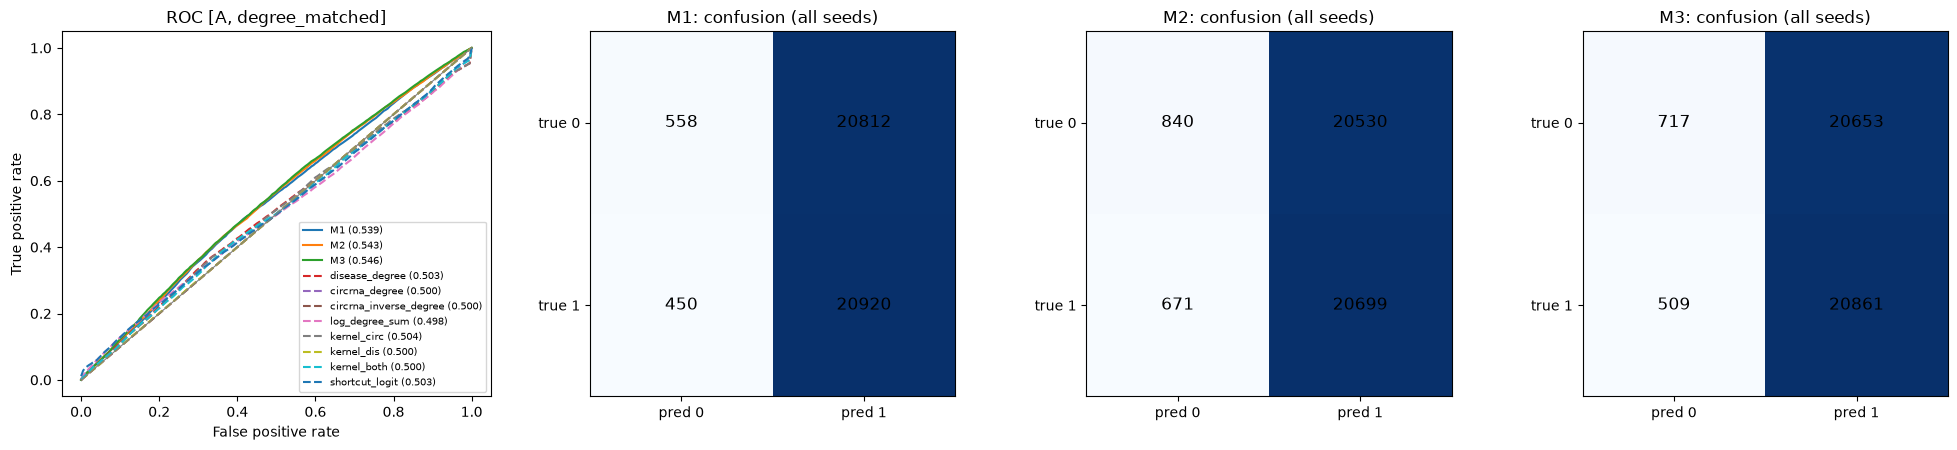


AUROC by circRNA status [A, degree_matched] (mean over seeds):
                          stratum   pos   neg    M1    M2    M3 disease_degree shortcut_logit
warm (circRNA has training pairs)  6800  6800 0.539 0.554 0.555          0.555          0.483
          cold (circRNA has none) 14570 14570 0.539 0.537 0.542          0.478          0.511


In [23]:
# 10_protocol_ladder - Cell 13: pair-level report for the run set in RUN: metrics, baselines from TRAINING pairs only, and AUROC split by whether the circRNA has training pairs
from sklearn.linear_model import LogisticRegression
from circmtl import ladder as L
RUN = "A"                                                    # same value as in Cell 12
SCHEME = {"A": "degree_matched", "C": "uniform_pair", "C2": "uniform_test_circ"}[RUN]
nC, nD = gd.N["circRNA"], gd.N["disease"]
if "_bs_host" not in globals():
    _bs_host = baseline_scores                                # the host-gene version from Cell 1
PAIR = {"on": True, "tag": RUN}

def baseline_scores(d, kind):
    if not PAIR["on"]:
        return _bs_host(d, kind)
    out = np.zeros(len(d))
    for (s, k), ix in d.groupby(["seed", "fold"]).indices.items():
        fd = L.pair_level_fold(gd, int(s), int(k))
        Y = L.label_matrix(fd["disease_train"], nC, nD); dd, dc = Y.sum(0), Y.sum(1)
        c, t = d["c"].to_numpy()[ix], d["t"].to_numpy()[ix]
        if kind == "disease_degree":          sc = dd[t]
        elif kind == "circrna_degree":        sc = dc[c]
        elif kind == "circrna_inverse_degree": sc = -dc[c]
        elif kind == "log_degree_sum":        sc = np.log1p(dd[t]) + np.log1p(dc[c])
        elif kind.startswith("kernel_"):      sc = L.kernel_scores(Y)[kind][c, t]
        elif kind == "shortcut_logit":
            z = np.load(OUT / "frozen_pair" / f"neg{PAIR['tag']}_seed{int(s)}_fold{int(k)}.npz")
            pv = np.vstack([fd["disease_val"], z["neg_val"]]); yv_ = np.r_[np.ones(len(fd["disease_val"])), np.zeros(len(z["neg_val"]))]
            clf = LogisticRegression(C=1.0).fit(np.c_[np.log1p(dd[pv[:, 1]]), np.log1p(dc[pv[:, 0]])], yv_)    # fitted on validation only
            sc = clf.decision_function(np.c_[np.log1p(dd[t]), np.log1p(dc[c])])
        else:
            raise ValueError(kind)
        out[ix] = sc
    return out

P_R = pd.concat([pd.read_csv(f) for m in ("M1", "M2", "M3") for f in sorted((OUT / f"pred_{RUN}").glob(f"pred_{m}_seed*_fold*.csv"))], ignore_index=True)
print(f"run {RUN}: {P_R.groupby('model')[['seed', 'fold']].apply(lambda g: len(g.drop_duplicates()))[['M1', 'M2', 'M3']].to_dict()} seed-folds per model (expect 50 each)")
BL = ("disease_degree", "circrna_degree", "circrna_inverse_degree", "log_degree_sum", "kernel_circ", "kernel_dis", "kernel_both", "shortcut_logit")
R_tab, R_seed = report(P_R, ["M1", "M2", "M3"], tag=RUN, scheme=SCHEME, baselines=BL)

# AUROC split by whether the pair's circRNA has >= 1 training pair (removes the held-out artifact inside each stratum)
warm = np.zeros(len(P_R), bool)
for (s, k), ix in P_R.groupby(["seed", "fold"]).indices.items():
    dc = np.bincount(L.pair_level_fold(gd, int(s), int(k))["disease_train"][:, 0], minlength=nC)
    warm[ix] = dc[P_R["c"].to_numpy()[ix]] > 0
base = P_R[P_R["model"] == "M1"][["seed", "fold", "c", "t", "y"]].reset_index(drop=True)
warm_b = warm[(P_R["model"] == "M1").to_numpy()]
comp = {"disease_degree": baseline_scores(base, "disease_degree"), "shortcut_logit": baseline_scores(base, "shortcut_logit")}
rows = []
for name, msk in (("warm (circRNA has training pairs)", True), ("cold (circRNA has none)", False)):
    r = {"stratum": name}
    sel_b = warm_b == msk
    r["pos"], r["neg"] = int(base["y"][sel_b].sum()), int((1 - base["y"][sel_b]).sum())
    for m in ("M1", "M2", "M3"):
        g = P_R[(P_R["model"] == m).to_numpy() & (warm == msk)]
        a = [roc_auc_score(x["y"], x["score_rank"]) for _, x in g.groupby("seed") if 0 < x["y"].sum() < len(x)]
        r[m] = f"{np.mean(a):.3f}" if a else "n/a"
    for cname, v in comp.items():
        a = [roc_auc_score(base["y"][sel_b & (base["seed"] == s).to_numpy()], v[sel_b & (base["seed"] == s).to_numpy()]) for s in range(10)
             if 0 < base["y"][sel_b & (base["seed"] == s).to_numpy()].sum() < (sel_b & (base["seed"] == s).to_numpy()).sum()]
        r[cname] = f"{np.mean(a):.3f}" if a else "n/a"
    rows.append(r)
print(f"\nAUROC by circRNA status [{RUN}, {SCHEME}] (mean over seeds):")
print(pd.DataFrame(rows).to_string(index=False))
PAIR["on"] = False                                           # restore the host-gene baselines for earlier cells